# 03 · Entrenamiento baseline
CNN desde cero. Guarda checkpoints en `experiments/<fecha>_<nombre>/` y reanuda solo si se interrumpe: basta con volver a ejecutar la celda de entrenamiento.

Hiperparámetros: `configs/baseline.yaml`.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.train import load_config
cfg = load_config("configs/baseline.yaml")
RAW = cfg["data"]["raw_dir"]

I0000 00:00:1792941771.582478     998 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
from src.train import train

run_dir = train("configs/baseline.yaml", name="baseline")  # resume=False para forzar corrida nueva

GPUs detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1792862245.510294   20092 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:10:00.0, compute capability: 8.9


Corrida: experiments/20261024-1217_baseline (nueva)
Epoch 1/30


I0000 00:00:1792862251.054765   48874 cuda_dnn.cc:461] Loaded cuDNN version 92700


952/952 - 177s - 185ms/step - accuracy: 0.4543 - loss: 1.7219 - val_accuracy: 0.6903 - val_loss: 0.9968 - learning_rate: 0.0010
Epoch 2/30
952/952 - 153s - 160ms/step - accuracy: 0.8867 - loss: 0.3338 - val_accuracy: 0.8559 - val_loss: 0.4780 - learning_rate: 0.0010
Epoch 3/30
952/952 - 152s - 160ms/step - accuracy: 0.9515 - loss: 0.1530 - val_accuracy: 0.8625 - val_loss: 0.4444 - learning_rate: 0.0010
Epoch 4/30
952/952 - 152s - 160ms/step - accuracy: 0.9700 - loss: 0.0940 - val_accuracy: 0.9191 - val_loss: 0.2820 - learning_rate: 0.0010
Epoch 5/30
952/952 - 155s - 162ms/step - accuracy: 0.9749 - loss: 0.0791 - val_accuracy: 0.9554 - val_loss: 0.1314 - learning_rate: 0.0010
Epoch 6/30
952/952 - 153s - 160ms/step - accuracy: 0.9841 - loss: 0.0512 - val_accuracy: 0.9709 - val_loss: 0.0905 - learning_rate: 0.0010
Epoch 7/30
952/952 - 151s - 159ms/step - accuracy: 0.9846 - loss: 0.0508 - val_accuracy: 0.9966 - val_loss: 0.0139 - learning_rate: 0.0010
Epoch 8/30
952/952 - 155s - 163ms/step

In [9]:
run_dir = sorted(Path("experiments").glob("*_baseline"))[-1]
print(run_dir)

experiments/20261024-1217_baseline


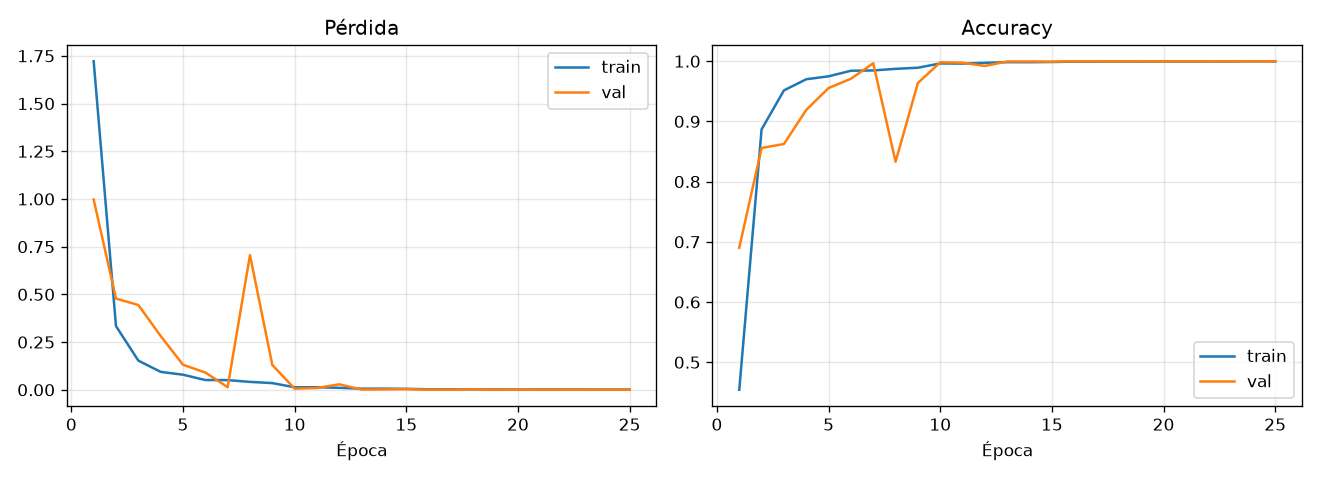

Accuracy en test: 1.0000


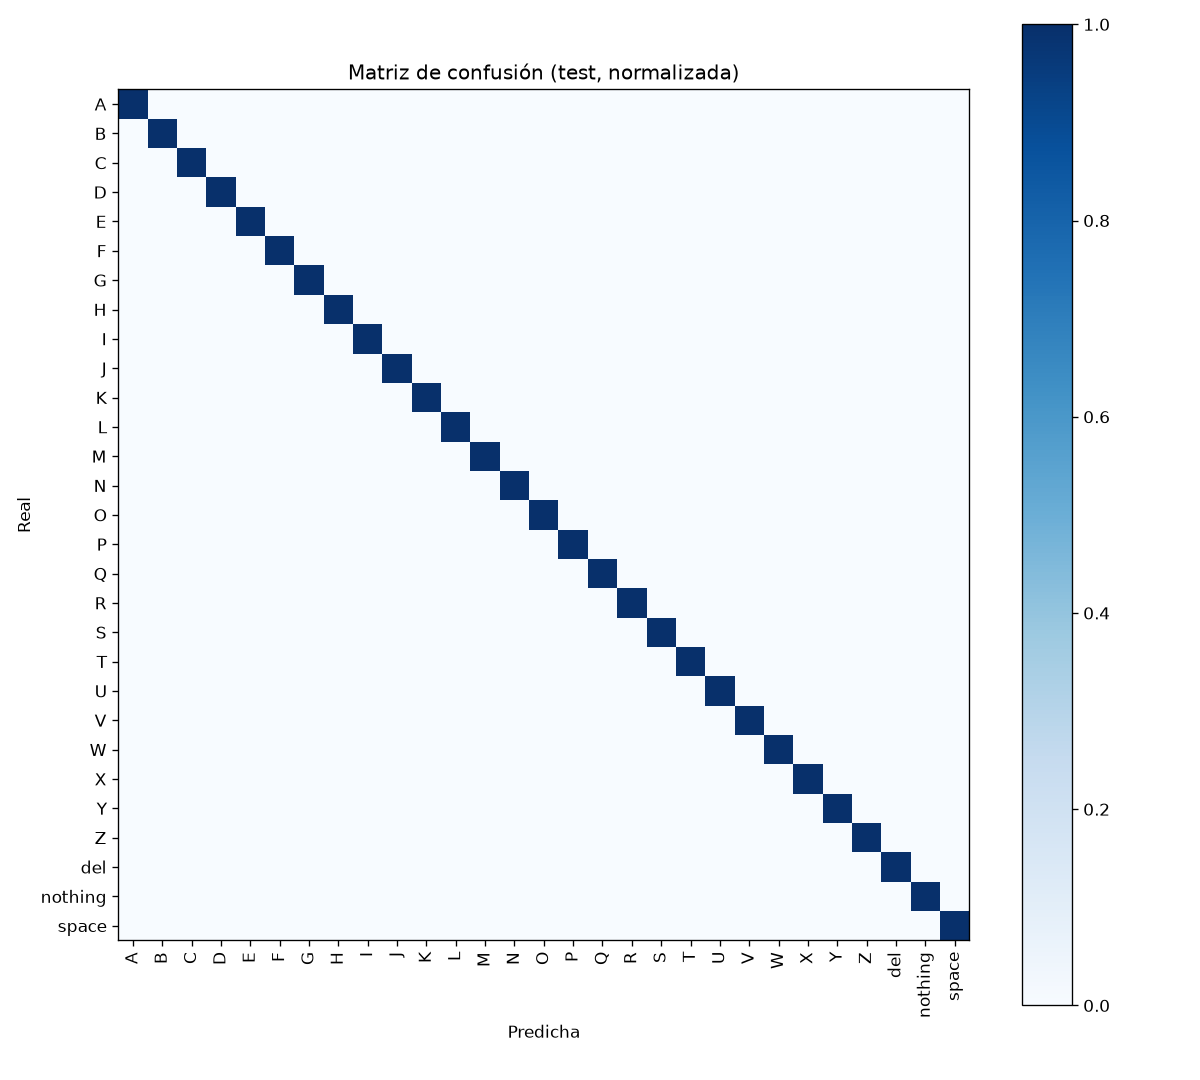

In [8]:
from IPython.display import Image, display
import json

display(Image(filename=str(run_dir / "curves.png")))
metrics = json.loads((run_dir / "metrics.json").read_text())
print(f"Accuracy en test: {metrics['accuracy']:.4f}")
display(Image(filename=str(run_dir / "confusion_matrix.png")))

# Evaluación de las predicciones de modelo (Overview Gráfica)

### Cargar modelo y test

In [2]:
import json
from tensorflow import keras
from src.data import make_splits
from src.visualize import load_test_samples, plot_single, plot_grid

run_dir = globals().get("run_dir") or sorted(Path("experiments").glob("*_baseline"))[-1]
model = keras.models.load_model(run_dir / "final" / "model.keras")
class_names = json.loads((run_dir / "final" / "classes.json").read_text())
img_size = tuple(cfg["data"]["img_size"])
test_df = (
    make_splits(RAW, cfg["data"]["split"], cfg["data"]["seed"])
    .query("split == 'test'").reset_index(drop=True)
)
print(run_dir, "|", len(test_df), "imágenes de test")

I0000 00:00:1792941786.895931     998 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:10:00.0, compute capability: 8.9


experiments/20261024-1217_baseline | 13050 imágenes de test


/home/juan/proyectos/asl-sign-language-recognition/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 58 variables whereas the saved optimizer has 62 variables. 
  saveable.load_own_variables(store)


### Una imagen por índice

I0000 00:00:1792941788.246610    1290 cuda_dnn.cc:461] Loaded cuDNN version 92700


Predicción: U | Prob. máx: 1.0000 | Real: U


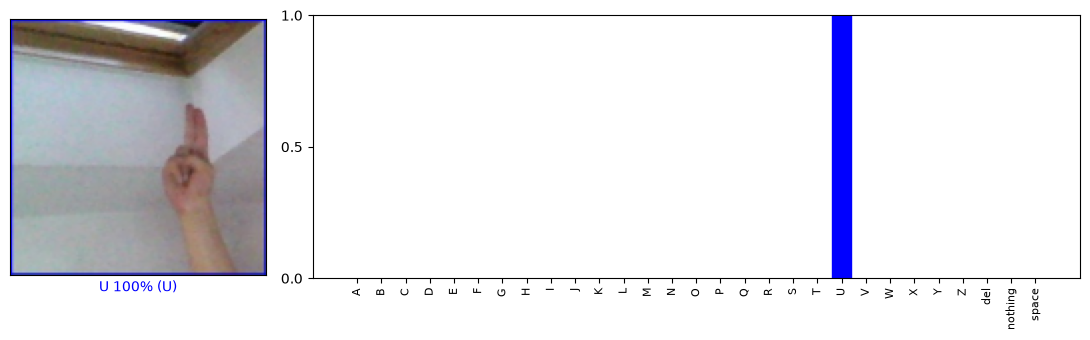

In [3]:
index = 100  # fila del test (0 a 13049)

images, y_true = load_test_samples(test_df, RAW, class_names, img_size, [index])
probs = model.predict(images, verbose=0)
pred = probs[0].argmax()
print(f"Predicción: {class_names[pred]} | Prob. máx: {probs[0].max():.4f} | Real: {class_names[y_true[0]]}")
plot_single(images[0], probs[0], class_names, y_true[0])

### Varias imágenes a la vez

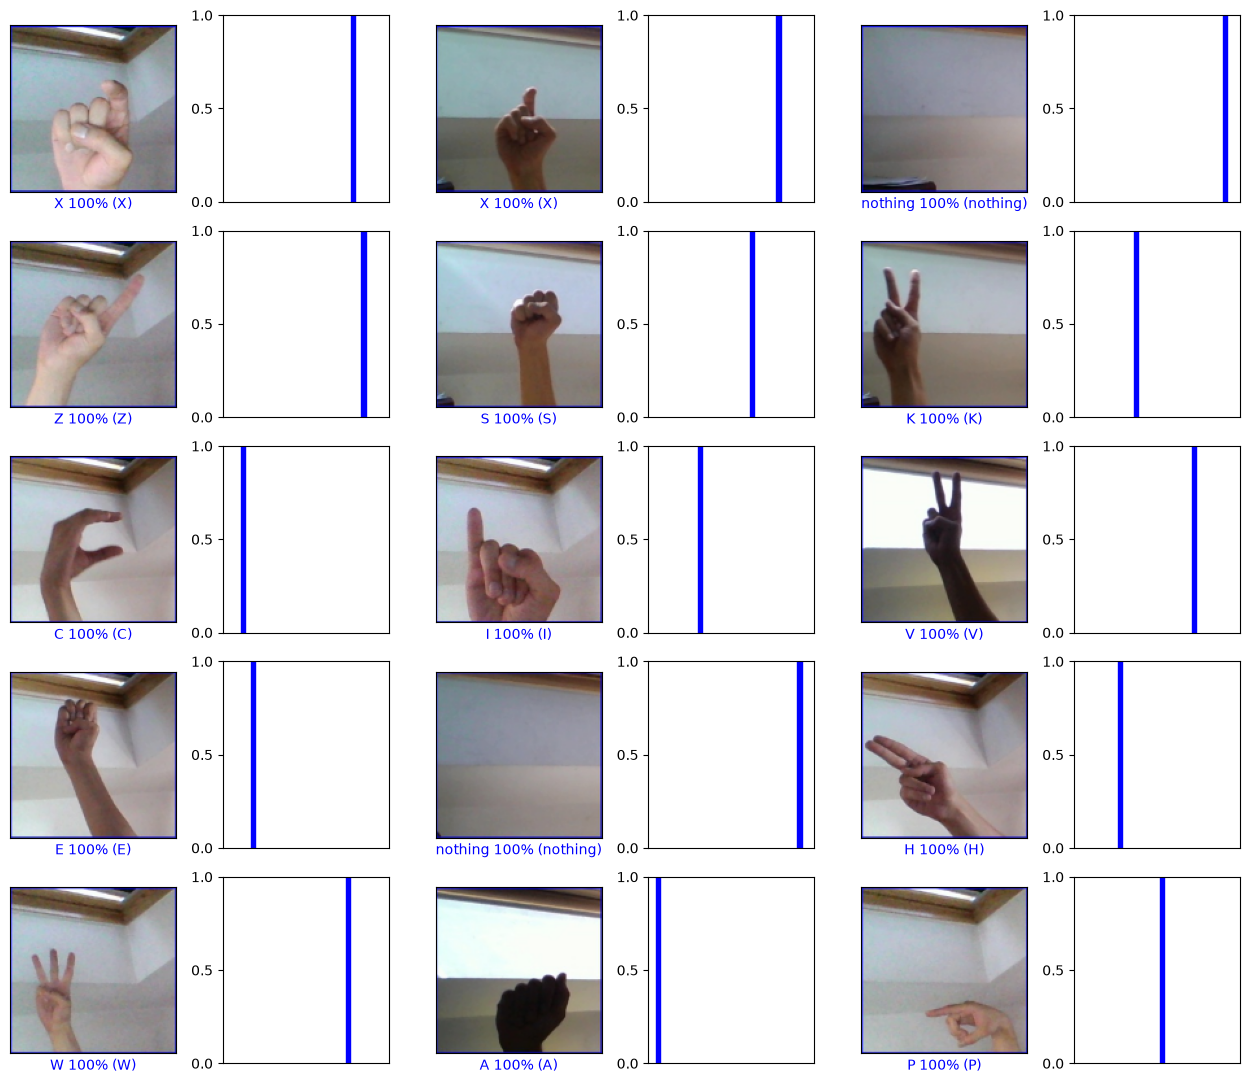

In [4]:
import numpy as np

n_rows, n_cols = 5, 3
rng = np.random.default_rng(0)  # cambia la semilla para ver otras imágenes
#indices = rng.choice(len(test_df), n_rows * n_cols, replace=False)
# Alternativa, imágenes consecutivas: indices = range(100, 100 + n_rows * n_cols)
indices = range(67, 67 + n_rows * n_cols)

images, y_true = load_test_samples(test_df, RAW, class_names, img_size, indices)
probs = model.predict(images, verbose=0)
plot_grid(images, probs, class_names, y_true, n_cols=n_cols)

---

### Fotos propias

In [5]:
from src.visualize import list_own_photos, predict_own_photos, plot_grid

photos = list_own_photos("data/mis_fotos", class_names)
res, images, probs = predict_own_photos(model, photos, class_names, img_size)
print(f"{len(res)} fotos | accuracy: {res.correct.mean():.2%}")
res.groupby("label").correct.agg(["mean", "count"]).rename(columns={"mean": "accuracy", "count": "fotos"})

6 fotos | accuracy: 50.00%


,accuracy,fotos
label,,
B,0.0,1
C,1.0,1
L,1.0,1
P,1.0,1
V,0.0,2


### Errores

In [6]:
errores = res[~res.correct]
print(f"{len(errores)} errores")
errores[["path", "label", "pred", "conf"]]

3 errores


,path,label,pred,conf
0,data/mis_fotos/B/B_01.jpg,B,W,0.455749
4,data/mis_fotos/V/V_01.jpg,V,O,0.497002
5,data/mis_fotos/V/V_02.jpg,V,B,0.894315


### Cuadrícula con todas las fotos (paginada)

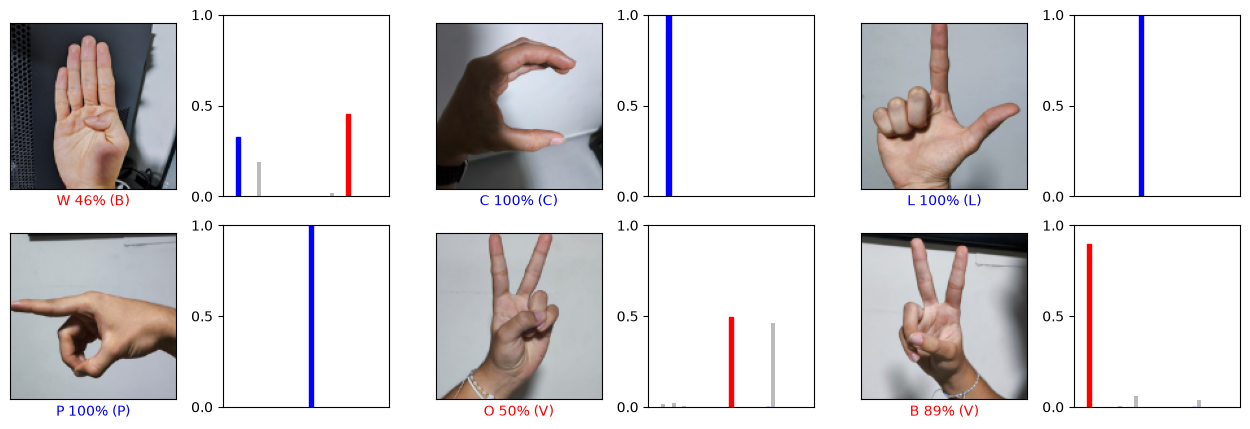

In [7]:
true_ids = res.true_id.to_numpy()
inicio, n = 0, 15  # cambia 'inicio' para ver las siguientes
sel = slice(inicio, inicio + n)
plot_grid(images[sel], probs[sel], class_names, true_ids[sel], n_cols=3)

### Solo los errores

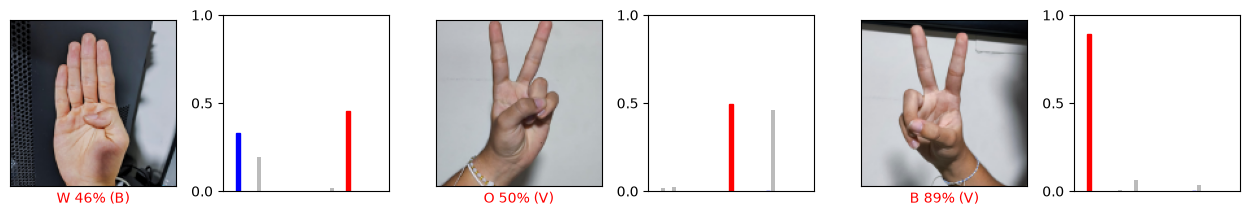

In [8]:
if len(errores):
    ids = errores.index.to_numpy()
    plot_grid(images[ids], probs[ids], class_names, true_ids[ids], n_cols=3)